# Lab 3 - HDBSCAN Hyperparameter Experiments
## JS08 - Hierarchical Clustering

**Name:** Tiara Febrianie  
**NIM:** 244107020097

This notebook studies the effects of `min_cluster_size`, `min_samples`, and `cut_distance`.

In [1]:
# Install HDBSCAN into the active notebook kernel environment.
%pip install hdbscan

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


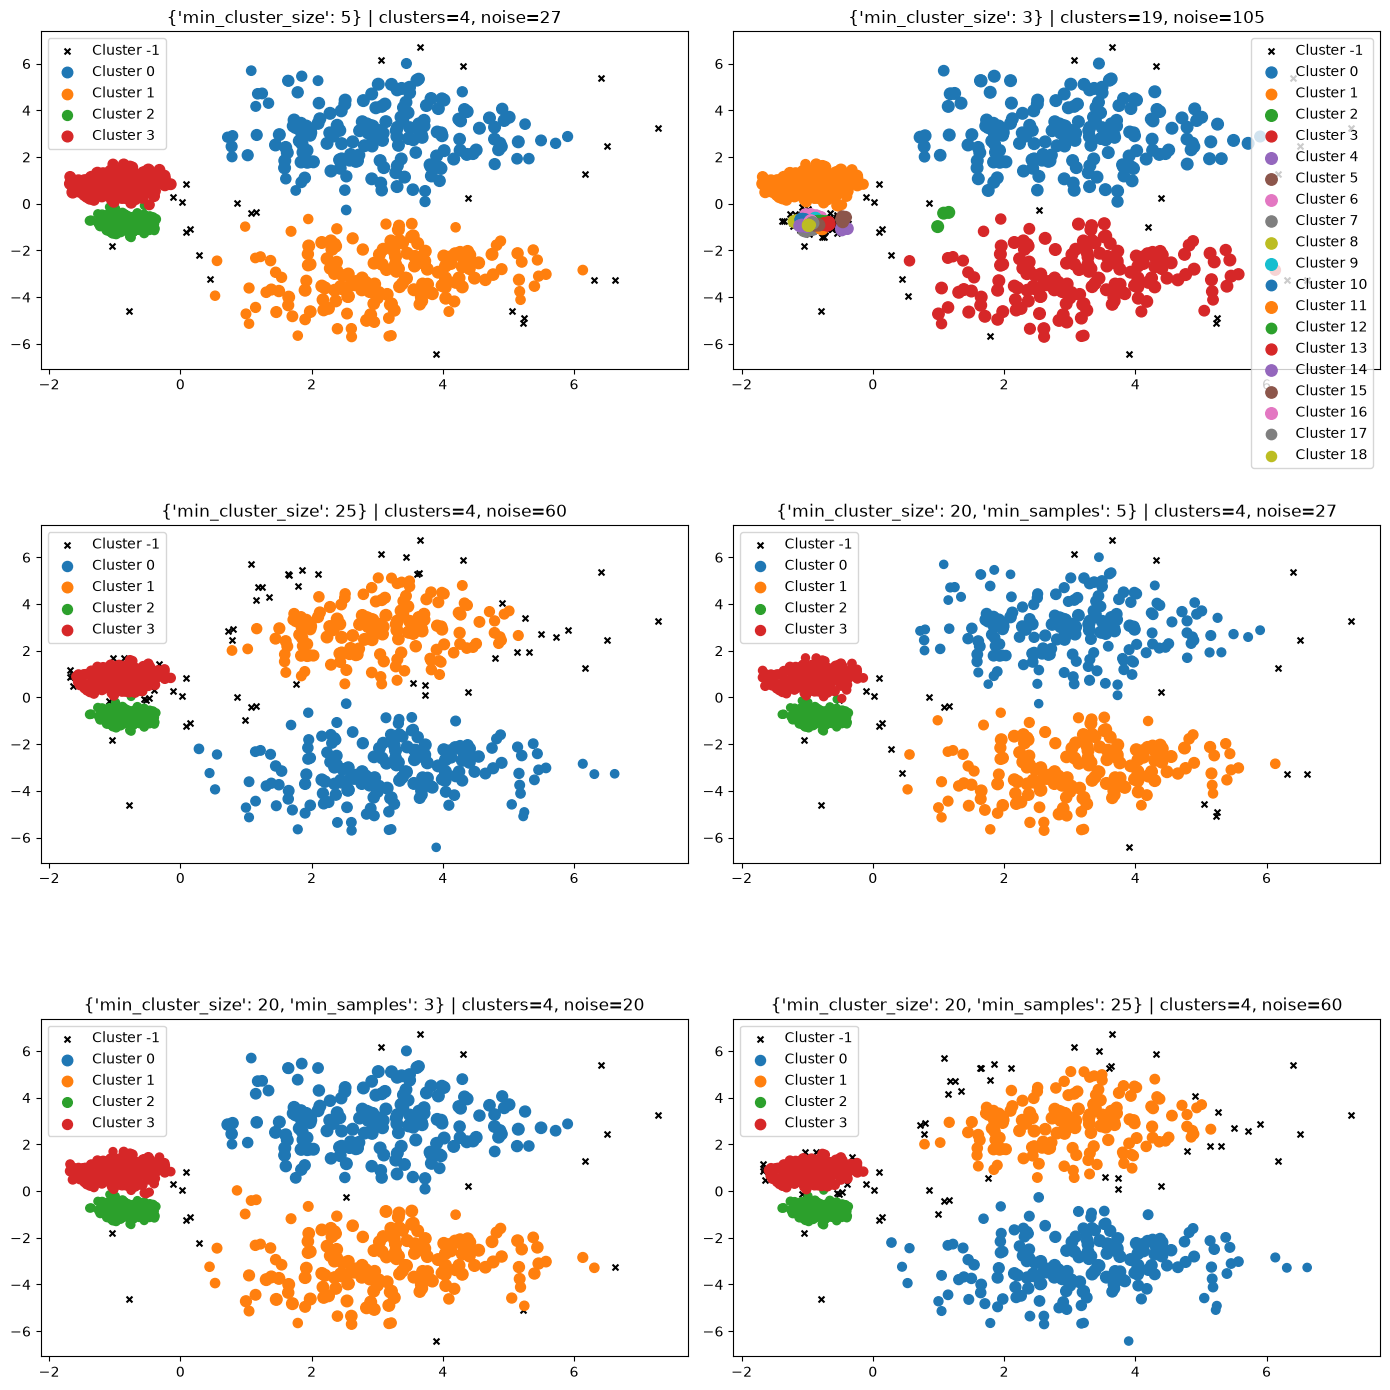

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score, davies_bouldin_score

def plot_result(X, labels, probabilities=None, title=''):
    probabilities = np.ones(len(X)) if probabilities is None else probabilities
    for cluster in sorted(set(labels)):
        mask = labels == cluster
        color = 'black' if cluster == -1 else plt.cm.tab10(cluster % 10)
        plt.scatter(X[mask, 0], X[mask, 1], c=[color], s=18 if cluster == -1 else 20 + 50 * probabilities[mask],
                    marker='x' if cluster == -1 else 'o', label=f'Cluster {cluster}')
    n = len(set(labels)) - int(-1 in labels)
    plt.title(f'{title} | clusters={n}, noise={(labels == -1).sum()}')
    plt.legend(loc='best')

centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(n_samples=750, centers=centers,
                            cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0)

experiments = []
for parameter_set in [
    {'min_cluster_size': 5}, {'min_cluster_size': 3}, {'min_cluster_size': 25},
    {'min_cluster_size': 20, 'min_samples': 5}, {'min_cluster_size': 20, 'min_samples': 3},
    {'min_cluster_size': 20, 'min_samples': 25}
]:
    model = hdbscan.HDBSCAN(**parameter_set).fit(X)
    labels = model.labels_
    experiments.append((parameter_set, model, labels))

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
for ax, (params, model, labels) in zip(axes.flat, experiments):
    plt.sca(ax)
    plot_result(X, labels, model.probabilities_, str(params))
plt.tight_layout()
plt.show()

,min_cluster_size,clusters,noise,silhouette,DBI,min_samples
0,5,4,27,0.621021,0.454722,NaN
1,3,19,105,0.463581,0.540093,NaN
2,25,4,60,0.640327,0.432609,NaN
3,20,4,27,0.621021,0.454722,5.0
4,20,4,20,0.612196,0.460163,3.0
5,20,4,60,0.640327,0.432609,25.0


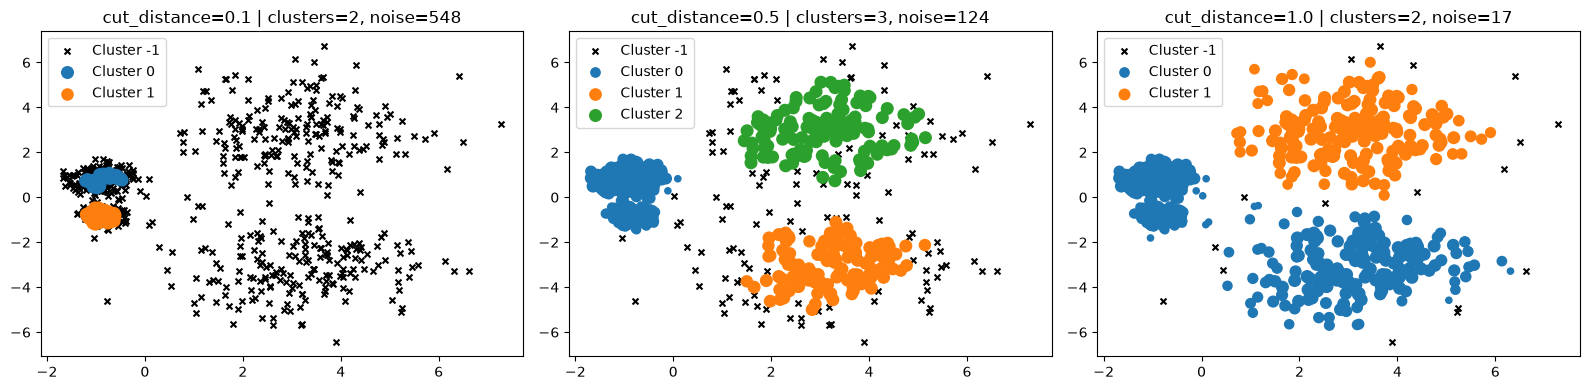

In [3]:
def valid_metrics(X, labels):
    mask = labels != -1
    usable_labels = labels[mask]
    if len(np.unique(usable_labels)) < 2:
        return np.nan, np.nan
    return silhouette_score(X[mask], usable_labels), davies_bouldin_score(X[mask], usable_labels)

rows = []
for params, model, labels in experiments:
    sil, dbi = valid_metrics(X, labels)
    rows.append({**params, 'clusters': len(set(labels)) - int(-1 in labels),
                 'noise': int((labels == -1).sum()), 'silhouette': sil, 'DBI': dbi})
results = pd.DataFrame(rows)
display(results)

base_model = hdbscan.HDBSCAN().fit(X)
cut_distances = [0.1, 0.5, 1.0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, distance in zip(axes, cut_distances):
    labels = base_model.dbscan_clustering(cut_distance=distance)
    plt.sca(ax)
    plot_result(X, labels, base_model.probabilities_, f'cut_distance={distance}')
plt.tight_layout()
plt.show()

### Conclusion
Increasing `min_cluster_size` generally demands denser, larger groups; increasing `min_samples` makes the model more conservative and can increase noise. `cut_distance` extracts different flat partitions from the same HDBSCAN hierarchy. For metrics, noise is excluded because treating every noise point as one ordinary cluster would distort the evaluation.